# New Yorker caption contest — Sections 8.1–8.4 and Pareto calibration
Original plot styling and separate plot outputs restored. Numerical and e-process corrections remain unchanged.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import brentq
from scipy.signal import fftconvolve
from scipy.stats import ttest_1samp
from tqdm.auto import tqdm

## Full Pareto-sum recursion — Table and Figure 1

In [28]:
# Numerical convolution evaluates the entire sum-tail recursion, not its asymptotic expansion.
K_VALUES = [2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
TARGET_ALPHA = 0.05
GRID_STEP = 0.005
LOWER_ALPHA = 0.03

def build_pareto_tails(max_k=max(K_VALUES), h=GRID_STEP, min_alpha=LOWER_ALPHA):
    # If Z=Y-1 and P(Y>=y)=1/y, P(Z in [jh,(j+1)h)) is known exactly.
    max_excess = max_k * (1 / min_alpha - 1) + 2
    n_bins = int(np.ceil(max_excess / h)) + 2
    edges = np.arange(n_bins+1) * h
    kernel = 1/(1+edges[:-1]) - 1/(1+edges[1:])
    pmf = kernel.copy()
    tails = {}
    for k in range(1, max_k+1):
        if k > 1:
            pmf = fftconvolve(pmf, kernel)[:n_bins]
            pmf = np.maximum(pmf, 0)
        if k in K_VALUES:
            tails[k] = np.concatenate(([1.], 1 - np.cumsum(pmf)))
    return tails

PARETO_TAILS = build_pareto_tails()

def B_K(k, a, tails=PARETO_TAILS, h=GRID_STEP):
    # Full recursion (approximated numerically on the bin grid): T_1(s)=1/s; T_k(s)=1/(s-k+1)+integral_1^(s-k+1) T_(k-1)(s-y)/y^2 dy.
    # Evaluate its convolution form on a fine grid, with midpoint/linear interpolation.
    if not (0 < a < 1): raise ValueError('a must be in (0,1)')
    threshold = (k/a-k)/h-k/2
    m = int(np.floor(threshold))
    if m < 0: return 1.
    frac = threshold-m
    t = tails[k]
    if m+1 >= len(t): raise ValueError('Increase max_excess or decrease LOWER_ALPHA')
    return float((1-frac)*t[m]+frac*t[m+1])

def inverse_B_K(k, alpha=TARGET_ALPHA):
    # Root of the full recursively computed bound B_K(alpha_prime)=alpha.
    return brentq(lambda a: B_K(k,a)-alpha, LOWER_ALPHA, alpha,
                  xtol=1e-12, rtol=1e-12)

alpha_prime_table = pd.DataFrame({
    'K': K_VALUES,
    'alpha_prime': [inverse_B_K(k) for k in K_VALUES],
    'B_K_0_05': [B_K(k,TARGET_ALPHA) for k in K_VALUES]
})
alpha_prime_table

,K,alpha_prime,B_K_0_05
0,2,0.046027,0.054583
1,5,0.042535,0.060045
2,10,0.040661,0.063868
3,15,0.039755,0.066038
4,20,0.039174,0.067567
5,25,0.038752,0.068753
6,30,0.038423,0.069725
7,35,0.038155,0.070550
8,40,0.037930,0.071269
9,45,0.037735,0.071907


### Figure 1 — Pareto bound and inverse calibration

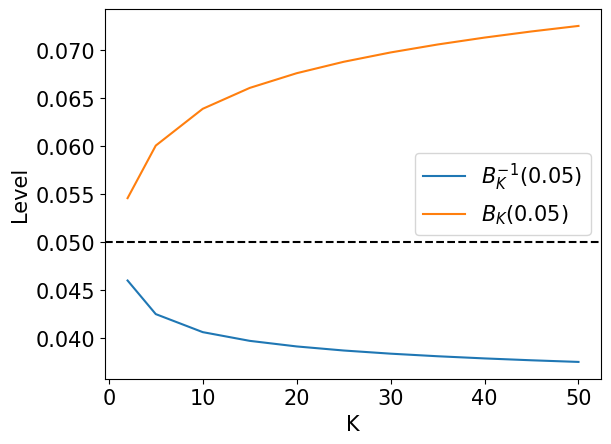

In [3]:
table = alpha_prime_table.to_dict(orient='records')
Ks = [2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

plt.rcParams.update({'font.size': 15})
plt.plot(Ks, [table[i]['alpha_prime'] for i in range(11)], color = 'C0', label = r'$B_K^{-1}(0.05)$')
plt.plot(Ks, [table[i]['B_K_0_05'] for i in range(11)], color = 'C1', label = r'$B_K(0.05)$')
plt.axhline(0.05, linestyle = 'dashed', color = 'black')
plt.xlabel('K')
plt.ylabel('Level')
plt.legend()
plt.show()

## Section 8.1 — Caption data and descriptive statistics

In [4]:
# Use the public data or a previously downloaded local copy.
DATA_URL = 'https://nextml.github.io/caption-contest-data/summaries/895.csv'
DATA_FILES = [Path('caption_data.csv'), Path('895.csv')]
DATA_FILE = next((path for path in DATA_FILES if path.exists()), DATA_URL)
df = pd.read_csv(DATA_FILE)
for column in ['mean','votes','not_funny','somewhat_funny','funny']:
    if column not in df.columns:
        raise ValueError(f'Missing data column: {column}')
for label, count_column in [('p1','not_funny'),('p2','somewhat_funny'),('p3','funny')]:
    df[label] = df[count_column] / df['votes']

# Scale p1, p2, and p3 to be valid sampling probabilities
df[['p1', 'p2', 'p3']] = df[['p1', 'p2', 'p3']].div(df[['p1', 'p2', 'p3']].sum(axis=1), axis=0)
df.head()

,caption,mean,precision,votes,not_funny,somewhat_funny,funny,p1,p2,p3
0,Do you think death rays would be considered el...,1.632287,0.012004,4014,2170,1150,694,0.540608,0.286497,0.172895
1,"Oh sure, now you look at a map.",1.632171,0.018294,1778,976,480,322,0.548931,0.269966,0.181102
2,I've never heard of planet fitness.,1.626694,0.017874,1918,1079,476,363,0.562565,0.248175,0.189260
3,"Wait, was it ""conquer the mall"" or ""conquer th...",1.624266,0.020087,1533,870,369,294,0.567515,0.240705,0.191781
4,"To Bed, Bath, and Beyond!",1.620504,0.013953,2975,1640,824,511,0.551261,0.276975,0.171765


In [5]:
# Section 8.1 — Dataset statistics reported in the paper.
print('Captions:', len(df))
print('Total votes:', int(df['votes'].sum()))
print('Highest average rating:', round(float(df['mean'].max()), 4))
print('Captions with mean > 1.5:', int((df['mean'] > 1.5).sum()))
df.head()

Captions: 4958
Total votes: 777820
Highest average rating: 1.6323
Captions with mean > 1.5: 65


,caption,mean,precision,votes,not_funny,somewhat_funny,funny,p1,p2,p3
0,Do you think death rays would be considered el...,1.632287,0.012004,4014,2170,1150,694,0.540608,0.286497,0.172895
1,"Oh sure, now you look at a map.",1.632171,0.018294,1778,976,480,322,0.548931,0.269966,0.181102
2,I've never heard of planet fitness.,1.626694,0.017874,1918,1079,476,363,0.562565,0.248175,0.189260
3,"Wait, was it ""conquer the mall"" or ""conquer th...",1.624266,0.020087,1533,870,369,294,0.567515,0.240705,0.191781
4,"To Bed, Bath, and Beyond!",1.620504,0.013953,2975,1640,824,511,0.551261,0.276975,0.171765


In [6]:
# Compute adjusted e-Holm e-values.
def e_holm(evals):
  if len(evals) == 0:
    return []

  pairs = sorted(enumerate(evals), key=lambda t: t[1], reverse = True)
  orig_idx = [i for i, _ in pairs]
  e_sorted = [x for _, x in pairs]
  n = len(e_sorted)

  e_adjusted = np.zeros(n)
  e_adjusted[n-1] = e_sorted[n-1]

  k = 1
  E_k = e_sorted[n-k]
  e_adj = float('inf')
  for r in range(1, n):
    i = n - 1 - r
    e = e_sorted[i]
    e_adj = e / (k+1) + E_k * k / (k+1)
    while(e_adj > e_sorted[n - k - 1]):
      E_k = E_k * k / (k+1) + e_sorted[n - k - 1] / (k+1)
      k = k + 1
      e_adj = e / (k+1) + E_k * k / (k+1)
      if k == n:
        break
    e_adjusted[i] = e_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = e_adjusted[sorted_pos]
  return adjusted


In [7]:
# Compute adjusted p-Holm p-values.
def p_holm(pvals):
  if len(pvals) == 0:
    return []

  pairs = sorted(enumerate(pvals), key=lambda t: t[1])
  orig_idx = [i for i, _ in pairs]
  p_sorted = [x for _, x in pairs]
  n = len(p_sorted)

  p_adjusted = np.zeros(n)
  p_adj = p_sorted[0] * n
  p_adjusted[0] = p_adj

  for i in range(1,n):
    p_i = p_sorted[i] * (n - i)
    if p_i > p_adj:
      p_adj = p_i
    p_adjusted[i] = min(p_adj, 1)

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = p_adjusted[sorted_pos]
  return adjusted

## Section 8.2 — e-Holm bandit: numerical results reported in the text

In [8]:
delta = 0.1
kappa = 8
q_grid = np.linspace(0, 0.999, 1000)
def ucb(n, mu):
  beta = np.log(kappa * np.log(2 * n / delta) / np.log(2))
  if mu == 0:
    return (1 - np.exp(- beta / n))
  elif mu == 1:
    return 1
  for q in q_grid[q_grid >= mu]:
    KL = mu * np.log(mu / q) + (1 - mu) * np.log((1 - mu) / (1 - q))
    if (KL > beta / n):
      return (q - 0.001)
  return 1

In [9]:
# Per-caption bandit sampler; record first adjusted rejection times.
def run_bandits(indices, num_steps, seed = 0):
  num_iter = num_steps
  epsilon = 0.4
  mu_0 = 0.25
  alpha = 0.05

  df_indices = df.iloc[indices].reset_index()
  n_arms = len(indices)


  pulls = np.ones(n_arms)
  np.random.seed(seed + 1)
  averages = np.array([np.random.choice([0, 0.5, 1], p=df_indices[['p1','p2','p3']].iloc[i]) for i in range(n_arms)])
  ucbs = np.array([ucb(pulls[i], averages[i]) for i in range(n_arms)])

  def eval(y, eta = 0.25):
    psi = np.log((1-mu_0) * np.exp(- eta * mu_0) + mu_0 * np.exp(eta * ( 1 - mu_0)))
    return np.exp(eta * (y - mu_0) - psi)

  e_processes = np.array([eval(averages[i]) for i in range(n_arms)])
  maxima = e_processes

  def pull_idx(idx):
    new_rating = np.random.choice([0, 0.5, 1], p = df_indices[['p1', 'p2', 'p3']].iloc[idx])
    n_pulls = pulls[idx]
    averages[idx] = averages[idx] * n_pulls / (n_pulls + 1) + new_rating / (n_pulls + 1)
    pulls[idx] = pulls[idx] + 1
    ucbs[idx] = ucb(pulls[idx], averages[idx])
    return new_rating

  reject_e = False
  pulls_e = (float('inf'), float('inf'))
  reject_p = False
  pulls_p = (float('inf'), float('inf'))
  reject_ep = False
  pulls_ep = (float('inf'), float('inf'))
  reject_pseudo_e = False
  pulls_pseudo_e = (float('inf'), float('inf'))

  from tqdm import tqdm
  np.random.seed(seed)
  for s in range(num_iter):


    pis = np.ones(n_arms) * epsilon / n_arms + np.array(ucbs == ucbs.max()) * (1 - epsilon) / np.sum(ucbs == ucbs.max())

    idx = np.random.choice(np.arange(n_arms), p = pis)
    pull = pull_idx(idx)
    e_processes[idx] = e_processes[idx] * eval(pull)
    maxima = np.maximum(maxima, e_processes)

    if not reject_e:
      best_adj_e = np.max(e_holm(e_processes))
      if best_adj_e > 1 / alpha:
        evals_adj = e_holm(e_processes)
        e_idx = np.argmax(evals_adj)
        pulls_arm = pulls[e_idx]
        pulls_e = (s, pulls_arm)
        reject_e = True

    if not reject_p:
      best_adj_p = np.min(p_holm(1 / maxima))
      if best_adj_p < alpha:
        pvals_adj = p_holm(1 / maxima)
        p_idx = np.argmin(pvals_adj)
        pulls_arm = pulls[p_idx]
        pulls_p = (s, pulls_arm)
        reject_p = True

    if not reject_ep:
      best_adj_ep = np.min(p_holm(1 / e_processes))
      if best_adj_ep < alpha:
        epvals_adj = p_holm(1 / e_processes)
        ep_idx = np.argmin(epvals_adj)
        pulls_arm = pulls[ep_idx]
        pulls_ep = (s, pulls_arm)
        reject_ep = True

    if not reject_pseudo_e:
      best_adj_pseudo_e = np.max(e_holm(maxima))
      if best_adj_pseudo_e > 1 / alpha:
        pseudo_evals_adj = e_holm(maxima)
        pseudo_idx = np.argmax(pseudo_evals_adj)
        pulls_arm = pulls[pseudo_idx]
        pulls_pseudo_e = (s, pulls_arm)
        reject_pseudo_e = True

  return pulls, averages, ucbs, maxima, e_processes, pulls_p, pulls_e, pulls_ep, pulls_pseudo_e

In [10]:
# Section 8.2 — 20 non-nulls, 30 nulls, 100 replicates, 10,000 pulls.
n = 50
n_1 = 20
n_0 = n - n_1
null_indices = df[df['mean'] <= 1.5].index[:n_0]
mix_indices = list(range(n_1)) + list(null_indices)
num_steps = 10000
num_iter = 100
alpha = 0.05
pulls_es = np.zeros((num_iter, 2))
pulls_ps = np.zeros((num_iter, 2))
for i in tqdm(range(num_iter), desc='Section 8.2'):
    _, _, _, _, _, pulls_p, pulls_e, _, _ = run_bandits(mix_indices, num_steps, i)
    pulls_es[i] = pulls_e
    pulls_ps[i] = pulls_p

# capping at 10,000 and unconditional improvement probabilities.
for index, label in [(0, 'T0 (all pulls)'), (1, 'T0,i* (original code: pulls of rejecting arm)')]:
    print(f'{label}: mean ratio = {np.mean(np.minimum(pulls_es[:,index],10000) / np.minimum(pulls_ps[:,index],10000)):.4f}; '
          f'P(e-Holm faster) = {np.mean(pulls_es[:,index] < pulls_ps[:,index]):.4f}')

# mean first-rejection times conditional on p-Holm rejecting.
for index, label in [(0, 'Overall pulls'), (1, 'Selected-arm pulls')]:
    valid = np.isfinite(pulls_ps[:, index])
    if valid.any():
        print(f'{label}: e-Holm mean = {pulls_es[valid,index].mean():.3f}; '
              f'p-Holm mean = {pulls_ps[valid,index].mean():.3f}')

Section 8.2:   0%|          | 0/100 [00:00<?, ?it/s]

T0 (all pulls): mean ratio = 0.9826; P(e-Holm faster) = 0.7000
T0,i* (original code: pulls of rejecting arm): mean ratio = 0.9724; P(e-Holm faster) = 0.7000
Overall pulls: e-Holm mean = 6340.457; p-Holm mean = 6453.468
Selected-arm pulls: e-Holm mean = 410.489; p-Holm mean = 418.606


## Section 8.3 — Factorial e-DAG: two-sided e-process (100 votes per pull, α=0.05)


In [11]:
# Caption features and eight factorial groups
cat_question = df.caption.apply(lambda x: '?' in x)
cat_exclamation = df.caption.apply(lambda x: '!' in x)
cat_length = df.caption.apply(lambda x: len(x))
median_length = np.median(cat_length)
cat_long = cat_length > median_length
df['question'] = cat_question
df['exclamation'] = cat_exclamation
df['long'] = cat_long
df['length'] = cat_length
df['type'] = df.question * 4 + df.exclamation * 2 + df.long
df.groupby('type')['mean'].agg(['count','mean'])

,count,mean
type,,
0,1352,1.192932
1,1491,1.179738
2,264,1.180487
3,281,1.161622
4,829,1.189113
5,577,1.175264
6,61,1.189010
7,103,1.191214


In [12]:
beta_contrasts = np.array([
    # beta_1 = mu100 - mu000
    [-1,  0,  0,  0,  1,  0,  0,  0],

    # beta_2 = mu010 - mu000
    [-1,  0,  1,  0,  0,  0,  0,  0],

    # beta_3 = mu001 - mu000
    [-1,  1,  0,  0,  0,  0,  0,  0],

    # beta_12 = mu110 - mu100 - mu010 + mu000
    [ 1,  0, -1,  0, -1,  0,  1,  0],

    # beta_13 = mu101 - mu100 - mu001 + mu000
    [ 1, -1,  0,  0, -1,  1,  0,  0],

    # beta_23 = mu011 - mu010 - mu001 + mu000
    [ 1, -1, -1,  1,  0,  0,  0,  0],

    # beta_123 = mu111 - mu110 - mu101 - mu011 + mu100 + mu010 + mu001 - mu000
    [-1,  1,  1, -1,  1, -1, -1,  1],
], dtype=int)

In [13]:
def e_dag(evals, budget = 'primary'):
  # ignore three-way interaction
  adj_evals = np.zeros(7)
  for i in range(3):
    adj_evals[i] = evals[i] / 3
  adj_evals[3] = min((evals[0] + evals[1]) / 3, (evals[0] + evals[3] / 2) / 3, (evals[1] + evals[3] / 2) / 3, evals[3] / 3)
  adj_evals[4] = min((evals[0] + evals[2]) / 3, (evals[0] + evals[4] / 2) / 3, (evals[2] + evals[4] / 2) / 3, evals[4] / 3)
  adj_evals[5] = min((evals[1] + evals[2]) / 3, (evals[1] + evals[5] / 2) / 3, (evals[2] + evals[5] / 2) / 3, evals[5] / 3)
  adj_evals[6] = 1
  return adj_evals

def p_dag(pvals, budget = 'primary'):
  adj_pvals = np.zeros(7)
  for i in range(3):
    adj_pvals[i] = pvals[i] * 3
  adj_pvals[3] = max(min(pvals[0], pvals[1]) * 3, 3 * pvals[3], min(pvals[0], 2 * pvals[3]) * 3, min(pvals[1], 2 * pvals[3]) * 3)
  adj_pvals[4] = max(min(pvals[0], pvals[2]) * 3, 3 * pvals[4], min(pvals[0], 2 * pvals[4]) * 3, min(pvals[2], 2 * pvals[4]) * 3)
  adj_pvals[5] = max(min(pvals[1], pvals[2]) * 3, 3 * pvals[5], min(pvals[1], 2 * pvals[5]) * 3, min(pvals[2], 2 * pvals[5]) * 3)
  adj_pvals[6] = 1
  return adj_pvals

In [22]:
# Section 8.3: num_votes independent ratings are averaged per caption-selection round.
# Also initialize every caption with a batch of num_votes ratings.
def run_bandits_balanced(num_per_arm, num_steps, seed = 0, arm_seed = 0, checkpoints = None, lam = 0.04, num_votes = 100):
  if not isinstance(num_votes, (int, np.integer)) or num_votes < 1:
    raise ValueError("num_votes must be a positive integer")
  np.random.seed(arm_seed)
  indices = []
  for a in range(8):
    a_indices = np.random.choice(df[df['type'] == a].index, num_per_arm, replace = False)
    indices.extend(a_indices)

  num_iter = num_steps
  epsilon = 0.4
  mu_0 = 0.25
  alpha = 0.05

  df_indices = df.iloc[indices].reset_index()
  n_arms = len(indices)

  type_means = df_indices.groupby('type').agg({'mean':'mean'})
  betas = beta_contrasts @ type_means

  df_sim = pd.DataFrame(columns = ['pulls', 'averages', 'ucbs', 'type'])


  df_sim.pulls = np.ones(n_arms)
  df_sim.averages = np.array([
    np.random.choice([0, 0.5, 1], size=num_votes,
                     p=df_indices[['p1','p2','p3']].iloc[i]).mean()
    for i in range(n_arms)
  ])
  df_sim.ucbs = np.array([ucb(num_votes * df_sim.loc[i, 'pulls'], df_sim.loc[i, 'averages']) for i in range(n_arms)])
  df_sim['type'] = df_indices['type']

  type_averages = df_sim.groupby('type').agg({'averages':'mean'})
  beta_averages = beta_contrasts @ type_averages

  # pi >= 0.4/48 and |psi| <= 24 for any num_votes >= 1.
  # With lam=0.04, both one-step betting factors are >= 0.04.
  def eval(y, idx, pi, side = 1):
    type_idx = df_indices['type'][idx]
    beta_values = np.array([a[0] for a in beta_averages.values])
    psi = beta_values + beta_contrasts[:,type_idx] * (1 / num_per_arm) / pi * (y - type_averages.loc[type_idx,'averages'])
    return (1 + side * lam * psi)

  e_processes_pos = np.ones(7)
  e_processes_neg = np.ones(7)
  e_processes = np.ones(7)
  maxima = e_processes.copy()

  def pull_idx(idx, pi):
    new_rating = np.random.choice(
      [0, 0.5, 1], size=num_votes,
      p=df_indices[['p1', 'p2', 'p3']].iloc[idx]
    ).mean()
    n_pulls = df_sim.loc[idx, 'pulls']
    # Maintain separate one-sided processes, then average to form the two-sided e-process.
    e_processes_pos[:7] *= eval(new_rating, idx, pi, side = 1)
    e_processes_neg[:7] *= eval(new_rating, idx, pi, side = -1)
    e_processes[:7] = (e_processes_pos + e_processes_neg) / 2
    maxima[:7] = np.maximum(maxima, e_processes)
    df_sim.loc[idx, 'averages'] = df_sim.loc[idx, 'averages'] * n_pulls / (n_pulls + 1) + new_rating / (n_pulls + 1)
    df_sim.loc[idx, 'pulls'] = df_sim.loc[idx, 'pulls'] + 1
    df_sim.loc[idx, 'ucbs'] = ucb(num_votes * df_sim.loc[idx,'pulls'], df_sim.loc[idx, 'averages'])
    type_averages[:8] = df_sim.groupby('type').agg({'averages':'mean'})
    beta_averages[:7] = beta_contrasts @ type_averages

  reject_e = False
  pulls_e = float('inf')
  e_arm = None
  reject_p = False
  pulls_p = float('inf')
  reject_pseudo_e = False
  pulls_pseudo_e = float('inf')
  reject_ep = False
  pulls_ep = float('inf')

  checkpoint_evals = {}
  np.random.seed(seed)
  for s in range(num_iter):


    pis = np.ones(n_arms) * epsilon / n_arms + np.array(df_sim.ucbs == df_sim.ucbs.max()) * (1 - epsilon) / np.sum(df_sim.ucbs == df_sim.ucbs.max())

    idx = np.random.choice(np.arange(n_arms), p = pis)
    pull = pull_idx(idx, pis[idx])


    if not reject_e:
      best_adj_e = np.max(e_dag(e_processes)[3:6])
      if best_adj_e > 1 / alpha:
        evals_adj = e_dag(e_processes)
        e_idx = np.argmax(evals_adj[3:6])
        pulls_e = s
        reject_e = True
        e_arm = e_idx


    if not reject_p:
      best_adj_p = np.min(p_dag(1 / maxima)[3:6])
      if best_adj_p < alpha:
        pvals_adj = p_dag(1 / maxima)
        p_idx = np.argmin(pvals_adj[3:6])
        pulls_p = s
        reject_p = True

    if not reject_pseudo_e:
      best_adj_pseudo_e = np.max(e_dag(maxima)[3:6])
      if best_adj_pseudo_e > 1 / alpha:
        pseudo_evals_adj = e_dag(maxima)
        pseudo_idx = np.argmax(pseudo_evals_adj[3:6])
        pulls_pseudo_e = s
        reject_pseudo_e = True

    if not reject_ep:
      best_adj_ep = np.min(p_dag(1 / e_processes)[3:6])
      if best_adj_ep < alpha:
        epvals_adj = p_dag(1 / e_processes)
        ep_idx = np.argmin(epvals_adj[3:6])
        pulls_ep = s
        reject_ep = True

    if checkpoints is not None and (s + 1) in checkpoints:
      checkpoint_evals[s + 1] = np.asarray(e_dag(e_processes)[:6]).copy()

  result = (df_sim, maxima, e_processes, beta_averages,
            pulls_p, pulls_e, pulls_pseudo_e, pulls_ep, e_arm)
  return (*result, checkpoint_evals) if checkpoints is not None else result

In [23]:
# Section 8.3 — Fixed lambda=0.04, alpha=0.05, and 100 ratings per caption-selection round.
num_per_arm = 6
num_votes_dag = 100
num_steps_dag = 10000
num_iter_dag = 100
lambda_dag = 0.04

section83_records = []
for i in tqdm(range(num_iter_dag), desc='Section 8.3: lambda=0.04, alpha=0.05'):
    (_, _, _, _, pulls_p, pulls_e, pulls_pseudo_e, pulls_ep, _) = run_bandits_balanced(
        num_per_arm, num_steps_dag, seed=i, arm_seed=0, lam=lambda_dag,
        num_votes=num_votes_dag
    )
    section83_records.append({
        'seed': i, 'lambda': lambda_dag, 'alpha': 0.05,
        'num_votes': num_votes_dag,
        'T_e': pulls_e + 1 if np.isfinite(pulls_e) else np.inf,
        'T_p': pulls_p + 1 if np.isfinite(pulls_p) else np.inf,
        'T_pseudo_e': pulls_pseudo_e + 1 if np.isfinite(pulls_pseudo_e) else np.inf,
        'T_ep': pulls_ep + 1 if np.isfinite(pulls_ep) else np.inf,
    })

section83_results = pd.DataFrame(section83_records)
times_e = section83_results['T_e'].to_numpy()
times_p = section83_results['T_p'].to_numpy()
both_reject = np.isfinite(times_e) & np.isfinite(times_p)
section83_summary = pd.DataFrame([{
    'lambda': lambda_dag, 'alpha': 0.05,
    'num_votes': num_votes_dag, 'rounds': num_steps_dag,
    'e-DAG rejections': int(np.isfinite(times_e).sum()),
    'p-DAG rejections': int(np.isfinite(times_p).sum()),
    'pseudo-e-DAG rejections': int(np.isfinite(section83_results['T_pseudo_e']).sum()),
    'ep-DAG rejections': int(np.isfinite(section83_results['T_ep']).sum()),
    'P(e-DAG earlier)': float(np.mean(times_e < times_p)),
    'P(p-DAG earlier)': float(np.mean(times_p < times_e)),
    'mean e/p ratio when both reject': (
        float(np.mean(times_e[both_reject] / times_p[both_reject]))
        if both_reject.any() else np.nan
    ),
}])
print(f'Section 8.3: {num_iter_dag} replications; {num_steps_dag} caption-selection rounds;'
      f' {num_votes_dag} votes per round; alpha=0.05; lambda={lambda_dag}.')
print(section83_summary.round(4).to_string(index=False))
section83_results.to_csv('section83_batched100_alpha005_replicates.csv', index=False)


Section 8.3: lambda=0.04, alpha=0.05:   0%|          | 0/100 [00:00<?, ?it/s]

Section 8.3: 100 replications; 10000 caption-selection rounds; 100 votes per round; alpha=0.05; lambda=0.04.
 lambda  alpha  num_votes  rounds  e-DAG rejections  p-DAG rejections  pseudo-e-DAG rejections  ep-DAG rejections  P(e-DAG earlier)  P(p-DAG earlier)  mean e/p ratio when both reject
   0.04   0.05        100   10000               100               100                      100                100               1.0               0.0                           0.9446


## Section 8.4 — Fixed-sample FWER and power

In [30]:
ALPHA = 0.05
N = 50
N_ALT = 20
N_NULL = N-N_ALT
REPLICATIONS = 1000
OBS_PER_CAPTION = np.linspace(100, 1000, 10, dtype=int)
CALIBRATED_ALPHA_50 = inverse_B_K(N,ALPHA)

# The first 20 captions have the highest means; nulls are closest to the boundary.
alt_indices = np.arange(N_ALT)
null_indices = df.index[df['mean'] <= 1.5][:N_NULL].to_numpy()
assert len(null_indices) == N_NULL
selected_indices = np.concatenate((alt_indices, null_indices))
caption_probabilities = df.loc[selected_indices, ['p1','p2','p3']].to_numpy()
oracle_alternatives = np.concatenate(((df.loc[alt_indices,'mean'].to_numpy()-1)/2,
                                      np.full(N_NULL,.3)))

# Gaussian likelihood-ratio approximation for transformed ratings (0, 0.5, 1).
def fixed_sample_eval(y_bar, n_obs, mu_alt=.3, sigma=.5, mu_0=.25):
    return np.exp((mu_alt-mu_0)*y_bar*n_obs/sigma**2
                  -(mu_alt**2-mu_0**2)*n_obs/(2*sigma**2))

def compute_fixed_time_rates(n_obs, n_replications=REPLICATIONS, seed=0):
    np.random.seed(seed)
    out = np.zeros((n_replications, 4, 2))
    for rep in range(n_replications):
        samples = np.array([np.random.choice([1,2,3], size=n_obs, p=probs)
                            for probs in caption_probabilities])
        means = (samples.mean(axis=1)-1)/2
        e_values = fixed_sample_eval(means, n_obs)
        oracle_e_values = fixed_sample_eval(means, n_obs, mu_alt=oracle_alternatives)
        p_values = ttest_1samp(samples, 1.5, axis=1, alternative='greater').pvalue
        pseudo_e_values = 1/np.maximum(p_values, 1e-6)
        reject = [p_holm(p_values) <= ALPHA,
                  e_holm(e_values) >= 1/ALPHA,
                  e_holm(oracle_e_values) >= 1/ALPHA,
                  e_holm(pseudo_e_values) >= 1/CALIBRATED_ALPHA_50]
        for m, selection in enumerate(reject):
            out[rep,m,0] = np.any(selection[N_ALT:])
            out[rep,m,1] = np.mean(selection[:N_ALT])
    return out.mean(axis=0)

fixed_results = np.array([compute_fixed_time_rates(n_obs)
                          for n_obs in tqdm(OBS_PER_CAPTION, desc='Figure 12 simulations')])

Figure 12 simulations:   0%|          | 0/10 [00:00<?, ?it/s]

### Figure 12 — FWER

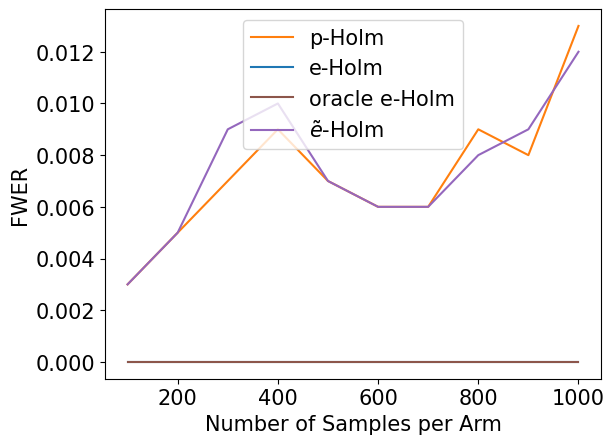

In [31]:
num_per_arms = OBS_PER_CAPTION
fwers = fixed_results[:,:,0]
powers = fixed_results[:,:,1]
plt.rcParams.update({'font.size': 15})
methods = ['p', 'e', 'oracle e', r"$\tilde e$"]
colors = ['C1', 'C0', 'C5', 'C4']
for i in [0,1,2,3]:
  plt.plot(num_per_arms, fwers[:,i], label = f'{methods[i]}-Holm', color = colors[i])
  plt.xlabel('Number of Samples per Arm')
  plt.ylabel('FWER')
  plt.legend()
plt.show()

### Figure 12 — Power

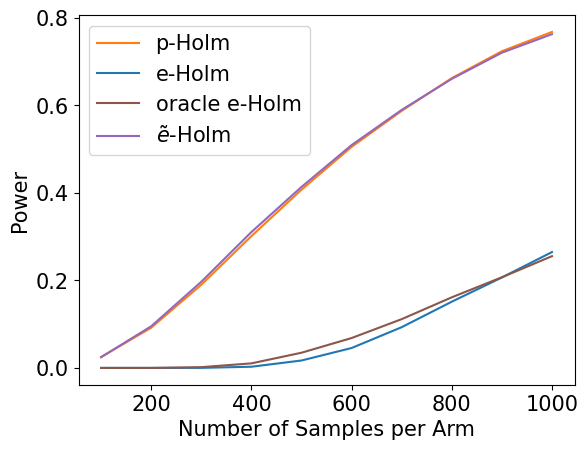

In [32]:
plt.rcParams.update({'font.size': 15})
for i in [0,1,2,3]:
  plt.plot(num_per_arms, powers[:,i], label = f'{methods[i]}-Holm', color = colors[i])
  plt.xlabel('Number of Samples per Arm')
  plt.ylabel('Power')
  plt.legend()
plt.show()